In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df= pd.read_csv(r"../data/processed/credit_card_fraud_cleaned.csv")

In [5]:
df

,TransactionID,TransactionDate,Amount,MerchantID,TransactionType,Location,IsFraud
0,1,2024-04-03,4189.27,688,refund,San Antonio,0
1,2,2024-03-19,2659.71,109,refund,Dallas,0
2,3,2024-01-08,784.00,394,purchase,New York,0
3,4,2024-04-13,3514.40,944,purchase,Philadelphia,0
4,5,2024-07-12,369.07,475,purchase,Phoenix,0
...,...,...,...,...,...,...,...
99995,99996,2024-06-07,1057.29,289,refund,San Antonio,0
99996,99997,2023-10-22,297.25,745,refund,San Antonio,0
99997,99998,2024-05-31,3448.56,690,purchase,San Antonio,0
99998,99999,2024-10-18,3750.79,644,purchase,Philadelphia,0


In [6]:
print("Dataset Shape:", df.shape)

Dataset Shape: (100000, 7)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   TransactionID    100000 non-null  int64  
 1   TransactionDate  100000 non-null  object 
 2   Amount           100000 non-null  float64
 3   MerchantID       100000 non-null  int64  
 4   TransactionType  100000 non-null  object 
 5   Location         100000 non-null  object 
 6   IsFraud          100000 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 5.3+ MB


In [8]:
display(df.describe())

,TransactionID,Amount,MerchantID,IsFraud
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,2497.092666,501.676070,0.010000
std,28867.657797,1442.415999,288.715868,0.099499
min,1.000000,1.050000,1.000000,0.000000
25%,25000.750000,1247.955000,252.000000,0.000000
50%,50000.500000,2496.500000,503.000000,0.000000
75%,75000.250000,3743.592500,753.000000,0.000000
max,100000.000000,4999.770000,1000.000000,1.000000


In [9]:
fraud_counts = df["IsFraud"].value_counts().sort_index()

print("Transaction Counts:")
print(fraud_counts)

Transaction Counts:
IsFraud
0    99000
1     1000
Name: count, dtype: int64


In [10]:
fraud_percentage = df["IsFraud"].value_counts(normalize=True) * 100

print("\nTransaction Percentages:")
print(fraud_percentage)


Transaction Percentages:
IsFraud
0    99.0
1     1.0
Name: proportion, dtype: float64


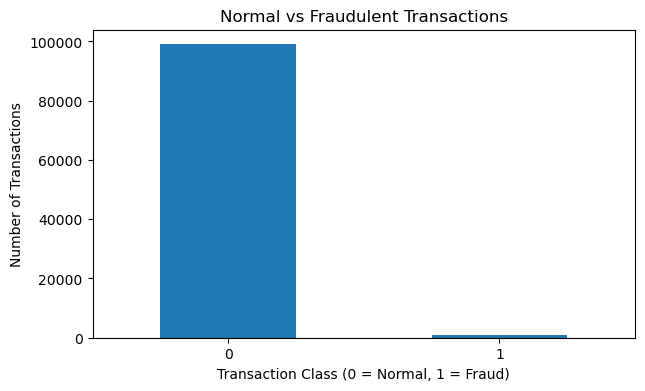

In [11]:
fraud_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()

In [12]:
display(
    df.groupby("IsFraud")["Amount"]
      .agg(["count", "mean", "median", "min", "max"])
)

,count,mean,median,min,max
IsFraud,,,,,
0,99000,2496.88992,2495.61,1.05,4999.77
1,1000,2517.16444,2543.43,5.56,4985.88


In [13]:
type_counts = pd.crosstab(
    df["TransactionType"],
    df["IsFraud"]
)

display(type_counts)

IsFraud,0,1
TransactionType,,
purchase,49376,493
refund,49624,507


In [14]:
type_fraud_rate = (
    df.groupby("TransactionType")["IsFraud"]
      .mean() * 100
)

print("Fraud Rate by Transaction Type (%):")
display(type_fraud_rate)

Fraud Rate by Transaction Type (%):


TransactionType
purchase    0.98859
refund      1.01135
Name: IsFraud, dtype: float64

In [15]:
location_counts = pd.crosstab(
    df["Location"],
    df["IsFraud"]
)

display(location_counts)

IsFraud,0,1
Location,,
Chicago,10098,95
Dallas,9977,99
Houston,9886,105
Los Angeles,9841,95
New York,9877,116
Philadelphia,9783,90
Phoenix,9861,99
San Antonio,9963,99
San Diego,9996,115


In [16]:
location_fraud_rate = (
    df.groupby("Location")["IsFraud"]
      .agg(["count", "sum", "mean"])
      .rename(columns={
          "count": "Total_Transactions",
          "sum": "Fraud_Count",
          "mean": "Fraud_Rate"
      })
)

location_fraud_rate["Fraud_Rate"] *= 100

display(
    location_fraud_rate.sort_values(
        "Fraud_Rate", ascending=False
    ).round(2)
)

,Total_Transactions,Fraud_Count,Fraud_Rate
Location,,,
New York,9993,116,1.16
San Diego,10111,115,1.14
Houston,9991,105,1.05
Phoenix,9960,99,0.99
San Antonio,10062,99,0.98
Dallas,10076,99,0.98
Los Angeles,9936,95,0.96
Chicago,10193,95,0.93
Philadelphia,9873,90,0.91


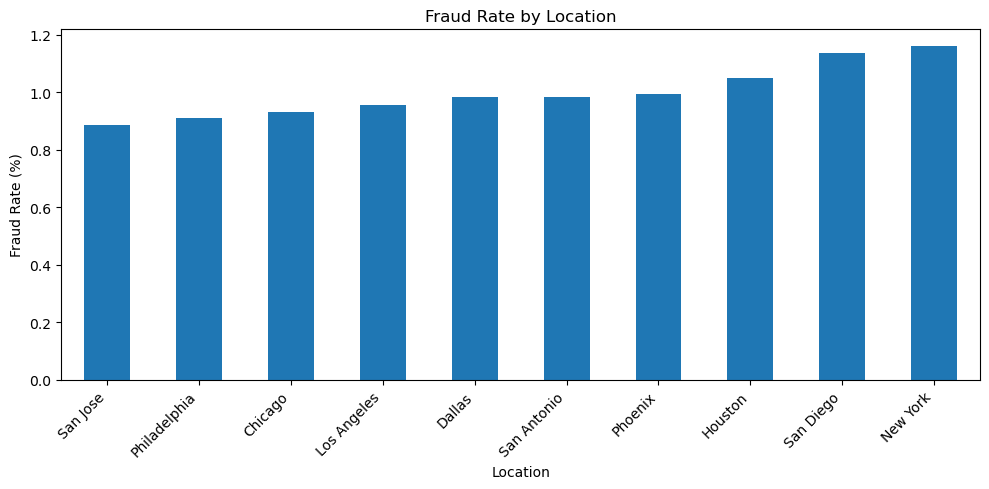

In [17]:
location_fraud_rate["Fraud_Rate"].sort_values().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Fraud Rate by Location")
plt.xlabel("Location")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [23]:
# Convert TransactionDate to datetime format
df["TransactionDate"] = pd.to_datetime(
    df["TransactionDate"],
    errors="coerce"
)

# Check the data type
print(df["TransactionDate"].dtype)

datetime64[ns]


In [26]:
df["YearMonth"] = df["TransactionDate"].dt.to_period("M").astype(str)
monthly_transactions = df.groupby("YearMonth").size()

display(monthly_transactions)

YearMonth
2023-10    2871
2023-11    8136
2023-12    8544
2024-01    8371
2024-02    7891
2024-03    8530
2024-04    8275
2024-05    8499
2024-06    8121
2024-07    8578
2024-08    8379
2024-09    8302
2024-10    5503
dtype: int64

In [25]:
monthly_fraud_rate = (
    df.groupby("YearMonth")["IsFraud"].mean() * 100
)

display(monthly_fraud_rate.round(2))

YearMonth
2023-10    0.91
2023-11    0.92
2023-12    0.92
2024-01    1.15
2024-02    1.22
2024-03    1.06
2024-04    0.85
2024-05    0.88
2024-06    0.83
2024-07    1.11
2024-08    1.07
2024-09    1.06
2024-10    0.96
Name: IsFraud, dtype: float64